## Employee Attrition - Financial Impact Analysis

**Data** https://www.kaggle.com/datasets/thedevastator/employee-attrition-and-factors?resource=download

**Objective** Evaluate employee attrition and estimate its financial impact on the organization through turnover-related cost analysis.

## Executive Summary

This analysis evaluates employee attrition patterns and estimates their financial impact on the organization.

The results show that employee turnover creates measurable financial costs for the business and is strongly associated with factors such as compensation level, overtime and employee age.

The findings may support management in workforce planning, retention strategy and cost optimization decisions.


**Stakeholder** The Finance, HR and Management teams require insights into employee turnover and its financial consequences in order to support budgeting, workforce planning, retention strategy and cost optimization decisions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\Kamila\Downloads\archive\HR_Analytics.csv.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [54]:
df.shape

(1470, 36)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Age                       1470 non-null   int64   
 1   Attrition                 1470 non-null   object  
 2   BusinessTravel            1470 non-null   object  
 3   DailyRate                 1470 non-null   int64   
 4   Department                1470 non-null   object  
 5   DistanceFromHome          1470 non-null   int64   
 6   Education                 1470 non-null   int64   
 7   EducationField            1470 non-null   object  
 8   EmployeeCount             1470 non-null   int64   
 9   EmployeeNumber            1470 non-null   int64   
 10  EnvironmentSatisfaction   1470 non-null   int64   
 11  Gender                    1470 non-null   object  
 12  HourlyRate                1470 non-null   int64   
 13  JobInvolvement            1470 non-null   int64 

In [8]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

## Data Quality Check
A data quality check was performed using 'df.isnull().sum()'.
No missing values were identified across all 35 columns.
The dataset was considered complate and ready for analysis without additional preprocessing related to null values.

## 1. Attrition Rate (%)

In [42]:
attrition_rate = df['Attrition'].value_counts(normalize=True) * 100
attrition_rate

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

## Attrition Rate Analysis
The attrition rate analysis shows that **16.12%** of employees left the company, while **83.88%** remained employed.
This indicates that employee turnover exists at a noticeable level and may represent a business risk for the organization.
Further analysis will focus on identifying which employee groups are most likely to leave and what factors may influence attrition.

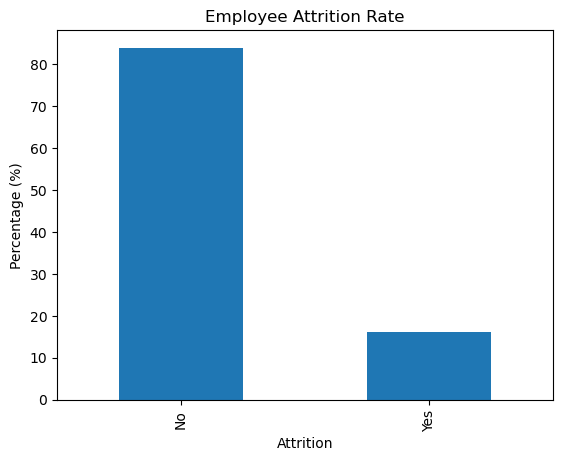

In [43]:
import matplotlib.pyplot as plt
attrition_rate.plot(kind='bar' )
plt.title('Employee Attrition Rate')
plt.xlabel('Attrition' )
plt.ylabel('Percentage (%)')
plt.show()

## Key Business Insight¶
The analysis shows that employee attrition affects approximately **1 in 6 employees** in the organization. With at attrition rate of **16.12%**, employee turnover generate additional recruitment, onboarding and training costs. This may also impact team productivity, operational continuity and knowledge retention within the company. Therefore, understanding the drivers of attrition is important from both HR and financial perspective.

## 2. Monthly Income vs Attrition

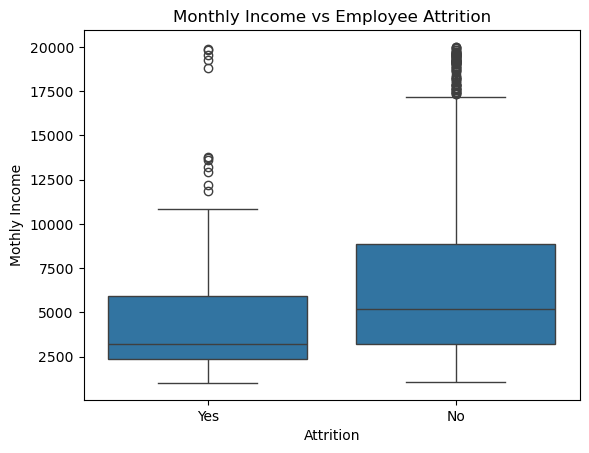

In [47]:
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df)
plt.title('Monthly Income vs Employee Attrition')
plt.xlabel('Attrition')
plt.ylabel('Mothly Income')
plt.show()

## Salary and Attrition Insight
The boxpol indicates that employees who left the company generally had lower monthly income compared with employees who stayed.
The median monthly income is visible lower in the **Attrition = Yes** group. 
This may suggest that compensation level could be one of the factors influencing employee turnover.
From a business and financial perspective, this insight may support management in reviewing compensation strategy, retension programs and workforce planning decisions.

## 3. Overtime vs Attrition 

In [48]:
overtime_attrition = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100
overtime_attrition

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


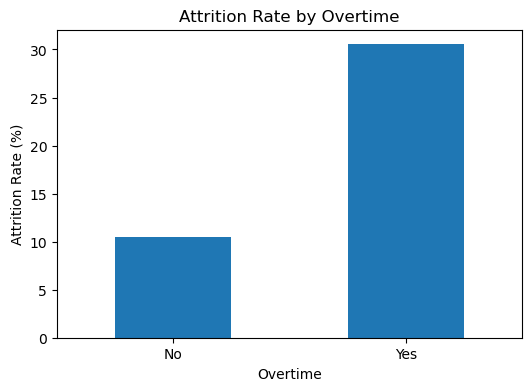

In [49]:
overtime_attrition['Yes'].plot(
    kind='bar',
    figsize=(6,4)
)
plt.title('Attrition Rate by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Overtime and Attrition Insight
The analysis shows a strong relationship between overtime and employee attrition.
Employees working overtime have a n attrition rate of **30.5%**, compared with **10.4%** among employees who do not work overtime. 
This means employees performing overtime are nearly **3 times more likely** to leave the company.
From a business perspective, this may indicate that workload, work-life balance and employee burnout are important drivers of turnover.
This insight may support management in reviewing overtime policies, workload capacity planning and employee wellbeing initiatives.

## 4. Age Groups vs Attrition

In [50]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[18, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65']
)

In [51]:
age_attrition = pd.crosstab(
    df['AgeGroup'],
    df['Attrition'],
    normalize='index'
) * 100

age_attrition

Attrition,No,Yes
AgeGroup,,
18-25,65.217391,34.782609
26-35,80.858086,19.141914
36-45,90.811966,9.188034
46-55,88.495575,11.504425
56-65,82.978723,17.021277


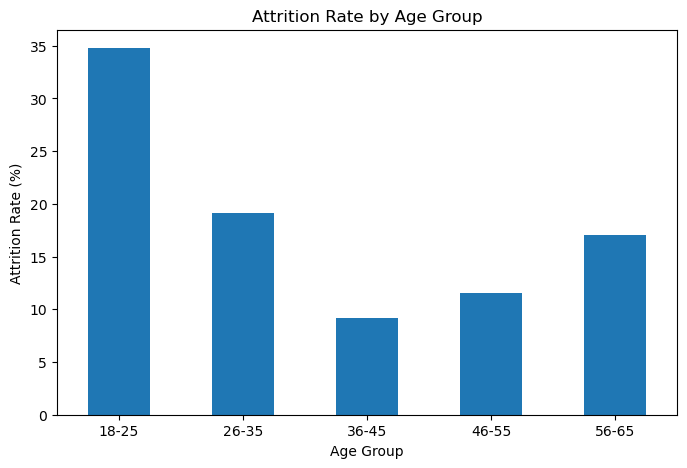

In [52]:
age_attrition['Yes'].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Attrition Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')

plt.xticks(rotation=0)
plt.show()

### Age Group and Attrition Insight
The analysis shows that the highest attrition rate appears among employees aged **18–25**, reaching approximately **34.8%**.
Employees aged **26–35** also show a relatively elevated attrition rate of approximately **19.1%**.
Attrition is lower among employees aged **36–45** and **46–55**, which may suggest stronger retention among more experienced employees.
From a business perspective, younger employees may require more focused retention actions, such as career development opportunities, mentoring, competitive compensation and stronger onboarding support.

## 4 Financial KPIs

## 1. Estimated Cost of Employee Turnover 
**Estimated Turnover Cost = N(attrition) x AvgMonthlyIncome x 6** 

**N** = number of employees who left the company **(Attrition = Yes)**

**AvgMonthlyIncome** = average monthly income 

**6** = estimated replacement cost factor, assuming that replacinng one employee costs approximately **six months of salary** including recruitment, onboarding, productivity loss and transition - related costs

In [35]:
n_attrition = df[df['Attrition'] == 'Yes'].shape[0]

avg_salary = df['MonthlyIncome'].mean()

estimated_turnover_cost = n_attrition * avg_salary * 6

estimated_turnover_cost

np.float64(9247168.297959182)

### Financial Impact Insight

The estimated cost of employee turnover is approximately **$924.168**.

This amount represents the potential financial impact associated with employees leaving the organization, based on the average monthly income and estimated replacement cost equivalent to six months of salary per employee.

The estimate may include:

- recruitment and hiring expenses
- onboarding and training costs
- temporary productivity loss
- knowledge transfer and transition-related business disruption

From a business perspective, employee attrition creates not only workforce challenges but also measurable financial costs for the organization.

Reducing attrition may contribute directly to cost optimization and improved operational efficiency.


## 2. Replacement Hiring Cost
**Replacemnt Hiring Cost = N(attrition) x AvgMonthlyIncome x 12 x 0.20** 

**N** = number of employees who left the company

**AvgMonthlyIncome** = average monthly income

**12** = annual salary conversion

**20%** = estimated recritment/replacement hiring cost

In [38]:
n_attrition = df[df['Attrition'] == 'Yes'].shape[0]

avg_salary = df['MonthlyIncome'].mean()

replacement_hiring_cost = n_attrition * avg_salary * 12 * 0.20

replacement_hiring_cost

np.float64(3698867.3191836732)

### Replacement Hiring Cost Insight

The estimated replacement hiring cost is approximately **$369.867**.

This amount represents the potential recruitment-related expenses required to replace employees who left the organization.

The estimate is based on the assumption that replacing one employee costs approximately *20% of annual salary*.

This may include:

- recruitment advertising
- candidate sourcing
- interview process
- HR administration
- hiring and replacement process costs

From a financial perspective, employee turnover generates direct hiring costs that impact workforce planning and overall organizational budget.

Reducing turnover may help lower recruitment expenses and improve cost efficiency.

## 3. Onboarding Cost 
**Onboarding Cost = N(attrition) x AvgMonthlyIncome x 2**

**N** = number of employees who left the company

**AvgMonthlyIncome** = average monthly income

**2** = 2 times monthly salaries

In [39]:
n_attrition = df[df['Attrition'] == 'Yes'].shape[0]

avg_salary = df['MonthlyIncome'].mean()

onboarding_cost = n_attrition * avg_salary * 2

onboarding_cost

np.float64(3082389.432653061)

### Onboarding Cost Insight

The estimated onboarding cost is approximately **$308,239**.

This amount represents the potential expenses associated with integrating and training new employees hired as replacements for employees who left the company.

The estimate assumes that onboarding one employee costs approximately *two monthly salaries*.

This may include:

- onboarding and orientation activities
- internal training and development
- manager and mentor support time
- administrative onboarding process
- adaptation and initial learning period costs

From a financial perspective, employee turnover creates additional onboarding expenses before new employees reach full productivity.

Reducing attrition may lower onboarding-related costs and improve operational efficiency.

## 4. Productivity Loss Estimate

**Productivity Loss Estimate = N(attrition) x AvgMonthlyIncome x 3 x 0.5**

**N** = number of employees who left the company

**AvgMonthlyIncome** = average monthly income

**3** = estimated ramp-up period (3 months)

**0.5** = assumed productivity gap (50%)

In [41]:
n_attrition = df[df['Attrition'] == 'Yes'].shape[0]

avg_salary = df['MonthlyIncome'].mean()

productivity_loss = n_attrition * avg_salary * 3 * 0.5

productivity_loss

np.float64(2311792.0744897956)

### Productivity Loss Estimate Insight

The estimated productivity loss related to employee turnover is approximately **$231,179**.

This amount reflects the temporary loss of productivity before newly hired employees reach full performance.

The estimate assumes a **3-month ramp-up period** with an average productivity loss of **50%** during onboarding and adaptation.

This may include:

- reduced productivity during the learning period
- time required to understand role responsibilities
- temporary performance gap before reaching full efficiency
- knowledge transfer delays
- operational disruption during employee transition

From a financial perspective, employee turnover impacts not only recruitment and onboarding costs, but also creates indirect productivity-related losses across the organization.

Reducing attrition may improve workforce efficiency, operational continuity and overall business performance.

### Promotion Frequency and Attrition Insight
The analysis shows a moderate relationship between promotion frequency and employee attrition.
The distribution of years since last promotion appears relatively similar between employees who left the company and those who remained.
This suggests that time since last promotion may have some impact on attrition, but it does not appear to be as strong as factors such as overtime, age or job satisfaction.
From a business perspective, career progression opportunities remain important for employee engagement and retention, although promotion frequency alone may not fully explain turnover behavior.

## Recommendations

Based on the analysis, the organization may consider:

- strengthening retention strategy for younger employees (18–25)
- reducing excessive overtime workload
- reviewing compensation strategy for lower-paid employee groups
- improving employee engagement and job satisfaction initiatives

# Final Business Conclusion

Employee attrition analysis shows that turnover is not only an HR issue, but also a measurable financial and operational challenge for the organization.

The overall attrition rate is **16.12%**, meaning approximately **1 in 6 employees** left the company.

The analysis identified the strongest attrition drivers as:

- overtime workload
- lower monthly income
- younger employee age group (**18–25**)

From a financial perspective, employee turnover generates significant business costs, including:

- **Estimated Cost of Employee Turnover:** $924,168
  
- **Replacement Hiring Cost:** $369,86

- **Onboarding Cost:** $308,23

- **Productivity Loss Estimate:** $231,179

These findings suggest that improving retention may not only reduce employee turnover, but also lower operational costs, improve productivity and support better workforce planning.